<a href="https://colab.research.google.com/github/anateresafalcao/Telecom-Physique-Strasbourg/blob/main/Copie_de_2026_IRIV_Morpho_math_TP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##scikit-image
Documentation de scikit-image :
https://scikit-image.org/docs/stable/

Consulter l'API pour la documentation des fonctions (paramètres, valeur de retour, etc.). La Gallery contient de nombreux exemples intéressants.


In [ ]:
# imports
import skimage
import numpy as np # tableaux
import scipy.ndimage as scp # correlation et convolution
import matplotlib.pyplot as plt # visionneur et tracés

from skimage import data # petite banque d'images
from skimage import util # conversions entier <-> flottants etc.
from skimage import filters as flt # 'filter' ou 'filters' suivant la version de skimage
from skimage import morphology,segmentation,io
%pylab inline
pylab.rcParams['figure.figsize'] = (10, 10)

Populating the interactive namespace from numpy and matplotlib


In [ ]:
# les données ne sont pas persistantes dans un document colab
# récupération des images sur un serveur git
!rm -r images/
!git clone https://github.com/bnaegel/m2i3d_morpho.git
!mv m2i3d_morpho images

rm: cannot remove 'images/': No such file or directory
Cloning into 'm2i3d_morpho'...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 71 (delta 3), reused 10 (delta 2), pack-reused 57 (from 1)
Receiving objects: 100% (71/71), 8.90 MiB | 34.90 MiB/s, done.
Resolving deltas: 100% (6/6), done.


## Morphologie mathématique
Documentation : http://scikit-image.org/docs/stable/api/skimage.morphology.html

### Elément structurant
Tableau numpy de type 'uint8' contenant des 0 et des 1. L'origine est au centre.
Exemple :

In [ ]:
# carré 3x3
se=np.ones([3,3],dtype='uint8')   # génère un tableau numpy de dimension (3,3) avec des 1
print(se)

[[1 1 1]
 [1 1 1]
 [1 1 1]]


In [ ]:
se=morphology.disk(1)     # méthode skimage pour génerer un él. structurant de type disk
print(se)
se=morphology.disk(5)     # méthode skimage pour génerer un él. structurant de type disk
print(se)

[[0 1 0]
 [1 1 1]
 [0 1 0]]
[[0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]


### Opérateurs
Les opérateurs de base prennent en paramètre une image et un élément structurant.
Exemple :

[[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]


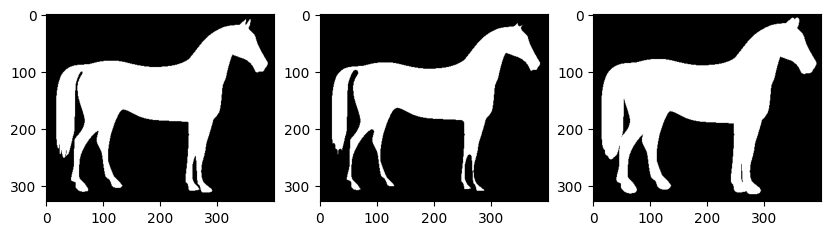

In [ ]:
# image binaire
H = data.horse() # L'objet est noir

H = np.logical_not(H) # L'objet est blanc

# éléments structurants
r = 3
B = morphology.disk(r) # mph.square(1+2*r), mph.diamond(r), mph.star(r)
print(B)

J = morphology.erosion(H, B)
K = morphology.dilation(H, B)

plt.subplot(1,3,1)
plt.imshow(H, cmap='gray')

plt.subplot(1,3,2)
plt.imshow(J, cmap='gray')

plt.subplot(1,3,3)
plt.imshow(K, cmap='gray')

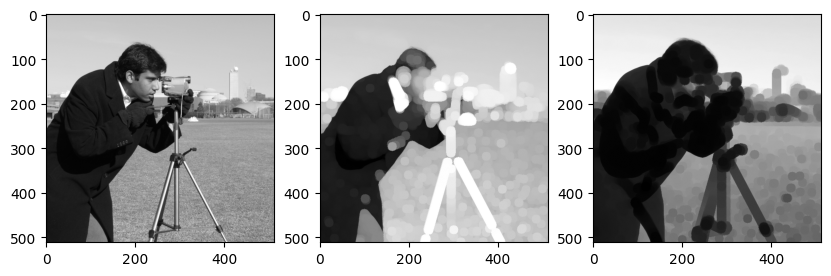

In [ ]:
# image en niveaux de gris
I=data.camera()
se=morphology.disk(10)
J=morphology.dilation(I,se)
K=morphology.erosion(I,se)

plt.subplot(1,3,1)
plt.imshow(I,cmap='gray')
plt.subplot(1,3,2)
plt.imshow(J,cmap='gray')
plt.subplot(1,3,3)
plt.imshow(K,cmap='gray')


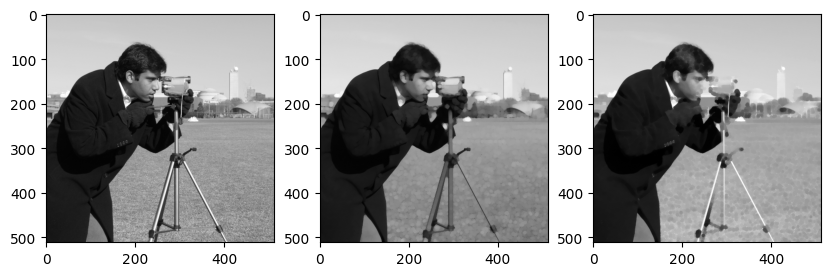

In [ ]:
# ouverture - fermeture
I=data.camera()
se=morphology.disk(3)
J=morphology.opening(I,se)
K=morphology.closing(I,se)

plt.subplot(1,3,1)
plt.imshow(I,cmap='gray')
plt.subplot(1,3,2)
plt.imshow(J,cmap='gray')
plt.subplot(1,3,3)
plt.imshow(K,cmap='gray')

### Filtrage morphologique

- Utiliser l'image `lines.png`
- Utiliser un filtre morphologique pour obtenir le même résultat que dans l'image `lines_res.png`

(640, 640)


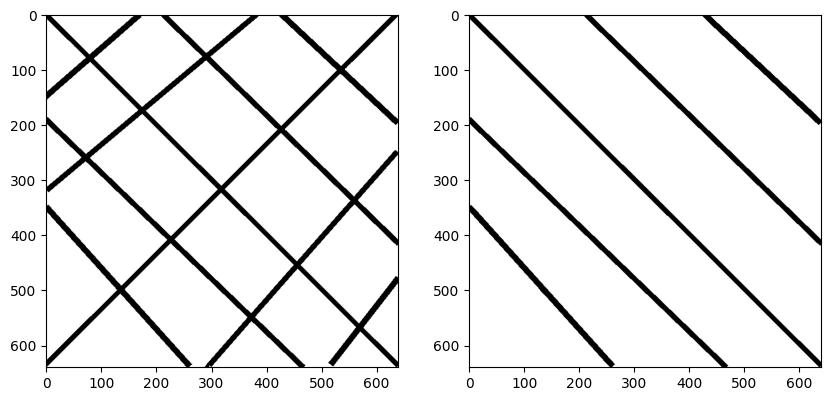

In [ ]:
f=skimage.io.imread('images/lines.png')[:,:,0]
g=skimage.io.imread('images/lines_res.png')

print(f.shape)

plt.subplot(1,2,1)
plt.imshow(f, cmap='gray')
plt.subplot(1,2,2)
plt.imshow(g)

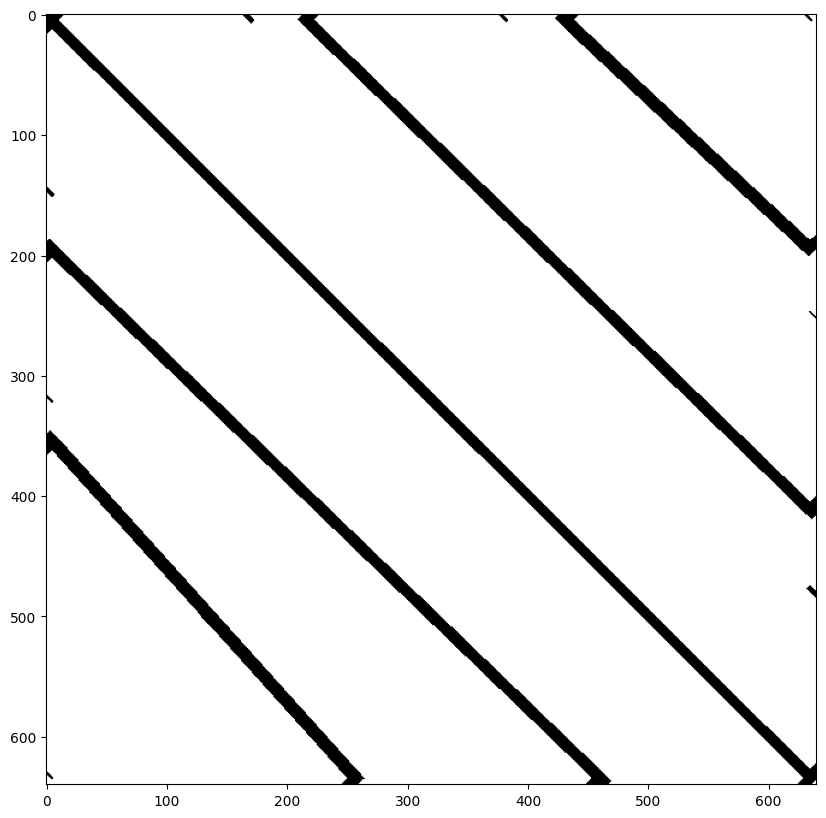

In [ ]:
l = 15 #qual é o l ideal?

se=np.ones([1,l],dtype='uint8')
se = skimage.transform.rotate(se,-45, resize=True,order=0)
#print(se)

# ou entao uso a matriz identidade, que funciona aqui pq o angulo é 45
# fazer isso é menos generalizado pq nem sepre quero esse angulo, por isso melhor usar o rotate
# se = np.eye(l)

g = skimage.morphology.closing(f,se)
plt.imshow(g, cmap='gray')


###  Extraction d'objets
Dans l'image `circuit.png` :
1. Effectuer un seuillage pour extraire les pistes et les pastilles du circuit électronique.
2. Utiliser un filtre morphologique pour éliminer les petites structures résiduelles
3. Utiliser un opérateur permettant de conserver uniquement les pastilles.
4. En déduire une opération permettant de conserver uniquement les pistes.

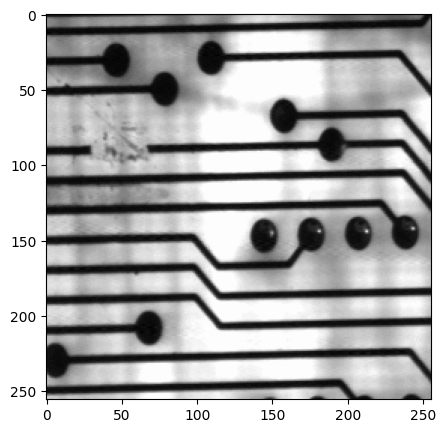

In [ ]:
I=skimage.io.imread('images/circuit.png')
plt.imshow(I,cmap='gray',vmin=0,vmax=255)
#plt.imshow((I<100).astype('uint8')*255,cmap='gray')

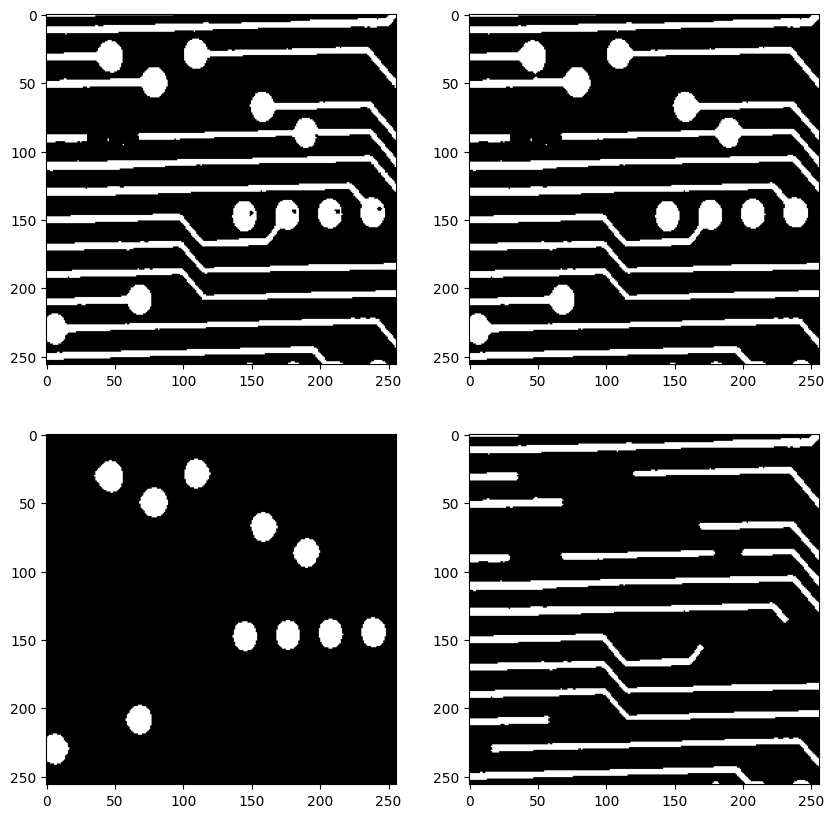

In [ ]:
# 1. seuillage
t = 80
I_seuil = (I < t).astype('uint8')
plt.subplot(2,2,1)
plt.imshow(I_seuil,cmap='gray')

# 2. eliminer petits trous (petite fermeture)
se = skimage.morphology.disk(2)
I_fermeture = skimage.morphology.closing(I_seuil,se)
plt.subplot(2,2,2)
plt.imshow(I_fermeture,cmap='gray')

# 3. conserver pastilles (ouverture disque)
se2 = skimage.morphology.disk(6)
I_pastilles = skimage.morphology.opening(I_fermeture,se2)
plt.subplot(2,2,3)
plt.imshow(I_pastilles,cmap='gray')

# 4. conserver pistes (ouverture)
se3 = np.ones([1,10])
I_pistes = I_fermeture-I_pastilles
I_finale = skimage.morphology.opening(I_pistes,morphology.disk(1)) #pra filtrar o ruido
plt.subplot(2,2,4)
plt.imshow(I_finale,cmap='gray')


### Correction d'illumination
Le but est de seuiller les nombres de l'image `numbers.png`

1. Seuiller l'image. Expliquer pourquoi, quelque soit le choix du seuil, le résultat ne sera pas satisfaisant.
2. Éliminer les chiffres de l'image à l'aide d'une opération morphologique.
3. En utilisant l'image précédente, corriger l'illumination de l'image originale.
4. Seuiller de façon à sélectionner les chiffres.

(117, 162)


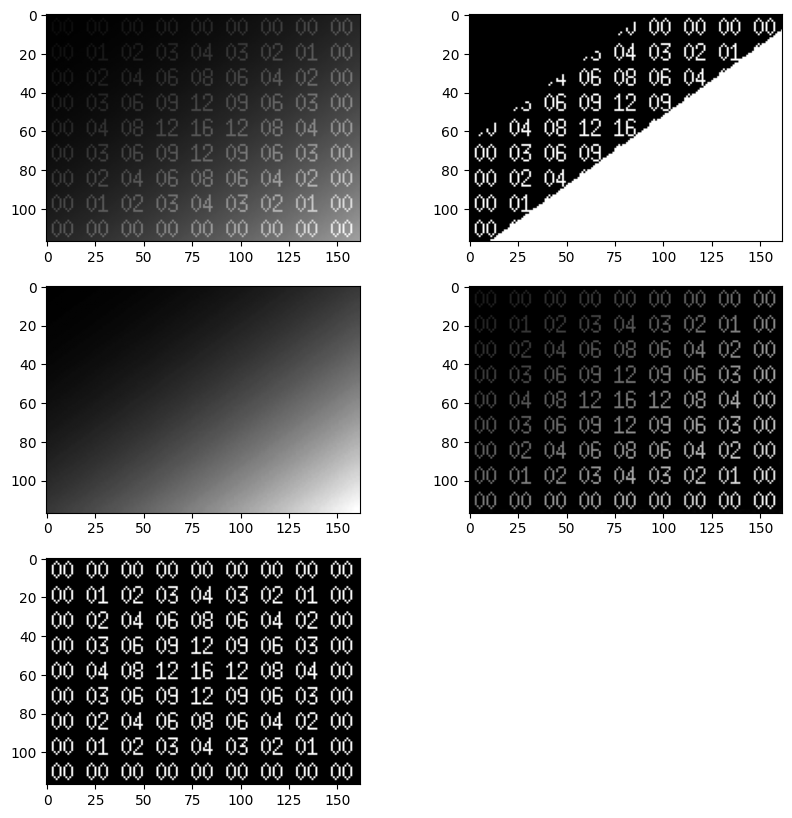

In [ ]:
f=skimage.io.imread('images/numbers.png')
plt.subplot(3,2,1)
plt.imshow(f,cmap='gray')
print(f.shape)

# 1. seuillage
t = 40
f_seuil = (f > t).astype('uint8')
plt.subplot(3,2,2)
plt.imshow(f_seuil,cmap='gray')
# a cause de l'ilumination de l'image le rsultat ne sera jamais satisfaisant
# il n'existe pas de sueil globale pour separer tout les chiffres

# 2 ouverture - nao funciona direto aqui
se = morphology.disk(3)
f_ouv = skimage.morphology.opening(f,se)
plt.subplot(3,2,3)
plt.imshow(f_ouv,cmap='gray')

g = morphology.white_tophat(f,se)
plt.subplot(3,2,4)
plt.imshow(g,cmap='gray')

res = (g>5).astype('uint8')
plt.subplot(3,2,5)
plt.imshow(res,cmap='gray')

### Restauration

Dans l'image `barrat4.jpg`, on souhaite éliminer les petites rayures noires. Proposer une solution et écrire le script correspondant.

(460, 638)


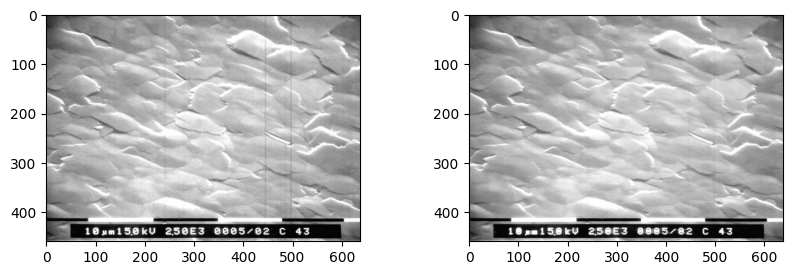

In [ ]:
f=skimage.io.imread('images/barrat4.jpg')
plt.subplot(3,2,1)
plt.imshow(f,cmap='gray')
print(f.shape)

# fermeture
# element structurant

l = 5
se = np.ones([1,l])

f_ferm = skimage.morphology.closing(f,se)
plt.subplot(3,2,2)
plt.imshow(f_ferm,cmap='gray')

### Fissures

Dans l'image `soil.tif`, on souhaite mettre en valeur les petites fissures du sol. Quel opérateur permet de faire cela ? Écrivez le script correspondant.

### Granulométrie

Dans l’image `barrat2.jpg` on souhaite obtenir la courbe granulométrique et le pattern spectrum pour des éléments structurants convexes de type disque de rayons croissants.
1. Écrivez une fonction permettant d’effectuer une succession d’ouvertures avec un élément structurant de type disque de taille i ∈ [1...10], et calculant après chaque ouverture le volume de l’image (somme des points de l’image)
2. On souhaite ensuite afficher la courbe granulométrique (taille de l’ouverture en abscisse, somme des points de l’image en ordonnée) ainsi que le pattern-spectrum (dérivée discrète de la courbe granulométrique).
3. En déduire la taille de la majorité des particules de l’image.